# Etapa 2 — Aprendizado Linear

**Alvo contínuo:** taxa de hospitalização por município (proporção de casos de dengue hospitalizados), para municípios com pelo menos 100 casos.

**Atributos:** proporção de idosos, crianças, casos com vômito, leucopenia, cefaleia e hipertensão, e o log do número de casos.

**Dados:** Sinan/Dengue 2026 (`DENGBR26.csv`), Portal de Dados Abertos do SUS. Rode as células em ordem.

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression, Ridge

SEED = 42
CAMINHO_CSV = "/content/DENGBR26.csv"   # ajuste se o arquivo estiver em outro lugar (ex.: no Drive)
ARQ_MUN = "municipios_etapa2.csv"       # tabela por município (cache)

## Funções auxiliares

In [13]:
def faixa_etaria(x):
    # NU_IDADE_N: 1o dígito = unidade (4 = anos), demais = valor. Ex.: 4048 = 48 anos
    if pd.isna(x):
        return "ignorado"
    x = int(x)
    unidade, valor = x // 1000, x % 1000
    anos = valor if unidade == 4 else 0     # horas, dias e meses = menos de 1 ano
    if anos < 12:
        return "crianca"
    elif anos < 60:
        return "adulto"
    return "idoso"


def r2(y, yhat):
    return 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)

## 1. Variável-alvo contínua: taxa de hospitalização por município

Cada linha da tabela é um município. Se o arquivo `municipios_etapa2.csv` já existe (de uma execução anterior), ele é reutilizado e o CSV grande não é lido.

In [14]:
if os.path.exists(ARQ_MUN):
    mun = pd.read_csv(ARQ_MUN)
    print("tabela por município carregada de", ARQ_MUN)
else:
    COLS2 = ["HOSPITALIZ", "NU_IDADE_N", "ID_MUNICIP", "SG_UF_NOT",
             "VOMITO", "LEUCOPENIA", "CEFALEIA", "HIPERTENSA"]
    d = pd.read_csv(CAMINHO_CSV, sep=",", encoding="latin-1",
                    usecols=COLS2, low_memory=False)
    print("registros no arquivo:", len(d))

    d = d[d["HOSPITALIZ"].isin([1, 2])].copy()
    print("com desfecho válido (HOSPITALIZ = 1 ou 2):", len(d))
    d["hosp"] = (d["HOSPITALIZ"] == 1).astype(int)
    d["faixa"] = d["NU_IDADE_N"].apply(faixa_etaria)
    d["idoso"] = (d["faixa"] == "idoso").astype(int)
    d["crianca"] = (d["faixa"] == "crianca").astype(int)
    for c in ["VOMITO", "LEUCOPENIA", "CEFALEIA", "HIPERTENSA"]:
        d[c] = (d[c] == 1).astype(int)       # 1 = sim; nulo e 2 contam como "não"

    mun = d.groupby("ID_MUNICIP").agg(
        n_casos=("hosp", "size"),
        taxa_hosp=("hosp", "mean"),
        p_idoso=("idoso", "mean"),
        p_crianca=("crianca", "mean"),
        p_vomito=("VOMITO", "mean"),
        p_leucopenia=("LEUCOPENIA", "mean"),
        p_cefaleia=("CEFALEIA", "mean"),
        p_hipertensao=("HIPERTENSA", "mean"),
        uf=("SG_UF_NOT", "first"),
    ).reset_index()

    print("municípios (todos):", len(mun))
    mun = mun[mun["n_casos"] >= 100].copy()
    mun.to_csv(ARQ_MUN, index=False)
    print("tabela salva em", ARQ_MUN)

print("municípios com >= 100 casos:", len(mun))
num = mun.drop(columns=["ID_MUNICIP", "uf"])
print(num.describe().round(3).to_string())
print("\ncorrelação com a taxa de hospitalização:")
print(num.corr()["taxa_hosp"].round(3).sort_values(ascending=False).to_string())
print("\n10 municípios de maior taxa:")
print(mun.sort_values("taxa_hosp", ascending=False).head(10).round(3).to_string(index=False))

tabela por município carregada de municipios_etapa2.csv
municípios com >= 100 casos: 436
         n_casos  taxa_hosp  p_idoso  p_crianca  p_vomito  p_leucopenia  p_cefaleia  p_hipertensao
count    436.000    436.000  436.000    436.000   436.000       436.000     436.000        436.000
mean     681.397      0.099    0.112      0.148     0.294         0.053       0.799          0.091
std     1916.413      0.125    0.065      0.093     0.088         0.079       0.101          0.059
min      100.000      0.000    0.004      0.007     0.040         0.000       0.327          0.000
25%      147.000      0.025    0.064      0.090     0.237         0.011       0.736          0.050
50%      234.500      0.053    0.100      0.127     0.293         0.028       0.819          0.079
75%      492.000      0.123    0.145      0.185     0.342         0.062       0.879          0.121
max    26446.000      0.927    0.520      0.673     0.698         0.603       1.000          0.425

correlação com a ta

## 2. Divisão treino/teste e regressão linear univariada (fórmula fechada)

Reta: y = b0 + b1·x, com b1 = Sxy / Sxx e b0 = média(y) − b1·média(x). O atributo escolhido é `p_crianca`, o mais correlacionado com a taxa.

treino: 348 | teste: 88

correlação entre os atributos:
               p_idoso  p_crianca  p_vomito  p_leucopenia  p_cefaleia  p_hipertensao  log_casos
p_idoso           1.00      -0.48     -0.12          0.05        0.12           0.67      -0.18
p_crianca        -0.48       1.00      0.18          0.17       -0.38          -0.38      -0.01
p_vomito         -0.12       0.18      1.00          0.13        0.31           0.05       0.04
p_leucopenia      0.05       0.17      0.13          1.00       -0.06           0.18      -0.03
p_cefaleia        0.12      -0.38      0.31         -0.06        1.00           0.26      -0.06
p_hipertensao     0.67      -0.38      0.05          0.18        0.26           1.00      -0.17
log_casos        -0.18      -0.01      0.04         -0.03       -0.06          -0.17       1.00

x_med=0.15155  y_med=0.09579
Sxy=1.66389  Sxx=3.27057  b1=Sxy/Sxx=0.50875
b0=y_med - b1*x_med=0.01869
SQ_erro=4.17195  SQ_total=5.01845  R2=0.16868

taxa_hosp = 0.0187 + 0.508

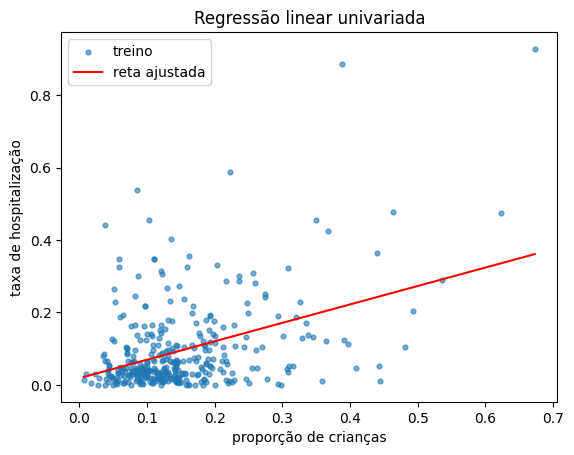

In [15]:
mun["log_casos"] = np.log10(mun["n_casos"])
FEATS = ["p_idoso", "p_crianca", "p_vomito", "p_leucopenia",
         "p_cefaleia", "p_hipertensao", "log_casos"]

mun_tr, mun_te = train_test_split(mun, test_size=0.2, random_state=42)
print("treino:", len(mun_tr), "| teste:", len(mun_te))

print("\ncorrelação entre os atributos:")
print(mun[FEATS].corr().round(2).to_string())

# regressão linear univariada (fórmula fechada)
x_tr, y_tr = mun_tr["p_crianca"].values, mun_tr["taxa_hosp"].values
x_te, y_te = mun_te["p_crianca"].values, mun_te["taxa_hosp"].values

xm, ym = x_tr.mean(), y_tr.mean()
Sxy = np.sum((x_tr - xm) * (y_tr - ym))
Sxx = np.sum((x_tr - xm) ** 2)
b1 = Sxy / Sxx
b0 = ym - b1 * xm

SQ_erro = np.sum((y_tr - (b0 + b1 * x_tr)) ** 2)
SQ_total = np.sum((y_tr - ym) ** 2)

print(f"\nx_med={xm:.5f}  y_med={ym:.5f}")
print(f"Sxy={Sxy:.5f}  Sxx={Sxx:.5f}  b1=Sxy/Sxx={b1:.5f}")
print(f"b0=y_med - b1*x_med={b0:.5f}")
print(f"SQ_erro={SQ_erro:.5f}  SQ_total={SQ_total:.5f}  R2={1 - SQ_erro / SQ_total:.5f}")
print(f"\ntaxa_hosp = {b0:.4f} + {b1:.4f} * p_crianca")
print("R2 treino:", round(r2(y_tr, b0 + b1 * x_tr), 4))
print("R2 teste: ", round(r2(y_te, b0 + b1 * x_te), 4))

plt.scatter(x_tr, y_tr, s=12, alpha=0.6, label="treino")
xs = np.linspace(x_tr.min(), x_tr.max(), 50)
plt.plot(xs, b0 + b1 * xs, color="red", label="reta ajustada")
plt.xlabel("proporção de crianças"); plt.ylabel("taxa de hospitalização")
plt.title("Regressão linear univariada"); plt.legend()
plt.show()

## 3. Regressão linear multivariada com gradiente descendente (do zero)

Atualização do Listing 2 (versão vetorizada): `w <- w + alpha * X^T (y - Xw) / N`. Os atributos são padronizados com média e desvio calculados só no treino.

MSE inicial -> final: 0.0236 -> 0.01017
R2 treino: 0.2949
R2 teste:  0.3114
max |w_gd - w_ne| = 5.3604039609855825e-14

coeficientes (atributos padronizados):
  intercepto      +0.0958
  p_idoso         +0.0009
  p_crianca       +0.0384
  p_vomito        +0.0243
  p_leucopenia    +0.0214
  p_cefaleia      -0.0262
  p_hipertensao   +0.0175
  log_casos       -0.0106


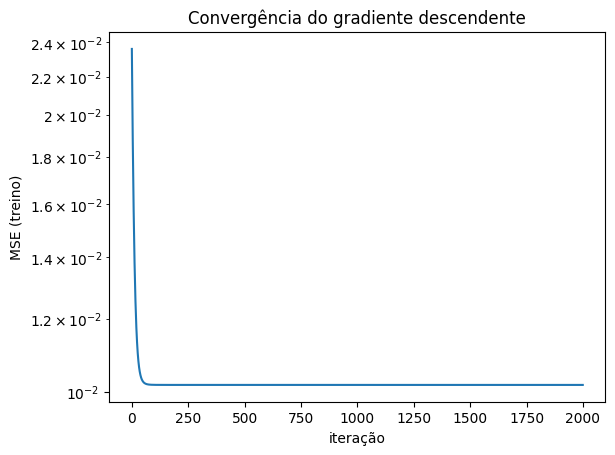

In [16]:
mu = mun_tr[FEATS].mean()
sd = mun_tr[FEATS].std()
Xtr = ((mun_tr[FEATS] - mu) / sd).values
Xte = ((mun_te[FEATS] - mu) / sd).values
ytr = mun_tr["taxa_hosp"].values
yte = mun_te["taxa_hosp"].values

# coluna de 1s para o intercepto
Xtr1 = np.c_[np.ones(len(Xtr)), Xtr]
Xte1 = np.c_[np.ones(len(Xte)), Xte]


def gd_linear(X, y, alpha=0.05, n_iter=2000):
    N, d = X.shape
    w = np.zeros(d)
    hist = []
    for it in range(n_iter):
        erro = y - X @ w              # y[j] - produto_interno(w, X[j])
        grad = X.T @ erro             # soma de erro * X[j]
        w = w + alpha * grad / N
        hist.append(np.mean(erro ** 2))
    return w, hist


w_gd, hist = gd_linear(Xtr1, ytr)
print("MSE inicial -> final:", round(hist[0], 5), "->", round(hist[-1], 5))
print("R2 treino:", round(r2(ytr, Xtr1 @ w_gd), 4))
print("R2 teste: ", round(r2(yte, Xte1 @ w_gd), 4))

# conferência: solução fechada (equações normais)
w_ne = np.linalg.solve(Xtr1.T @ Xtr1, Xtr1.T @ ytr)
print("max |w_gd - w_ne| =", float(np.max(np.abs(w_gd - w_ne))))

print("\ncoeficientes (atributos padronizados):")
for nome, coef in zip(["intercepto"] + FEATS, w_gd):
    print(f"  {nome:15s} {coef:+.4f}")

plt.plot(hist)
plt.xlabel("iteração"); plt.ylabel("MSE (treino)"); plt.yscale("log")
plt.title("Convergência do gradiente descendente")
plt.show()

## 4. Regularização L2 (Ridge) e curva de coeficientes vs. lambda

Custo: `J = (1/2N) * soma((y - Xw)^2) + (lambda/2) * soma(w_j^2)`, sem penalizar o intercepto. Atualização: `w <- w + alpha * [X^T (y - Xw)/N - lambda * w]`. O lambda é escolhido por validação cruzada 5-fold **dentro do treino**.

lambda=  0.0: max |GD - fechada| = 4.51e-17
lambda=  0.1: max |GD - fechada| = 3.99e-17
lambda=  1.0: max |GD - fechada| = 1.39e-17
lambda= 50.0: max |GD - fechada| = 3.61e-16

lambda ótimo (5-fold no treino): 0.2728 | R2 CV = 0.1926
OLS   : R2 treino=0.2949 | teste=0.3114
Ridge : R2 treino=0.2840 | teste=0.2839

coeficientes OLS -> Ridge:
  p_idoso         +0.0009 -> +0.0003
  p_crianca       +0.0384 -> +0.0307
  p_vomito        +0.0243 -> +0.0191
  p_leucopenia    +0.0214 -> +0.0196
  p_cefaleia      -0.0262 -> -0.0204
  p_hipertensao   +0.0175 -> +0.0113
  log_casos       -0.0106 -> -0.0089


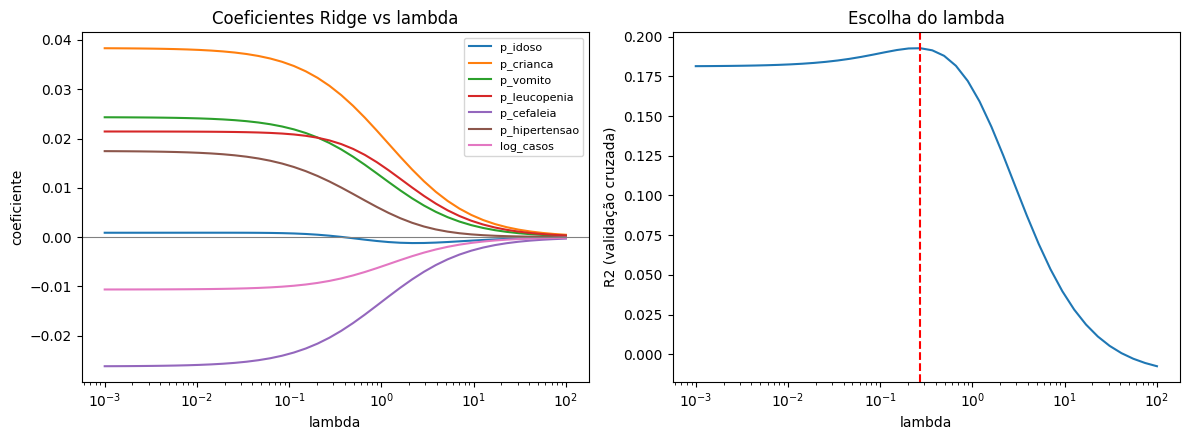

In [17]:
def ridge_gd(X, y, lam, n_iter=5000):
    N, d = X.shape
    L = np.linalg.eigvalsh(X.T @ X / N).max() + lam
    alpha = 1.0 / L                      # passo seguro para qualquer lambda
    w = np.zeros(d)
    pen = np.ones(d); pen[0] = 0         # não penaliza o intercepto
    for it in range(n_iter):
        erro = y - X @ w
        w = w + alpha * (X.T @ erro / N - lam * pen * w)
    return w


def ridge_fechada(X, y, lam):
    N, d = X.shape
    P = np.eye(d); P[0, 0] = 0
    return np.linalg.solve(X.T @ X / N + lam * P, X.T @ y / N)


# conferência: GD x solução fechada
for lam in [0.0, 0.1, 1.0, 50.0]:
    dif = np.max(np.abs(ridge_gd(Xtr1, ytr, lam) - ridge_fechada(Xtr1, ytr, lam)))
    print(f"lambda={lam:5}: max |GD - fechada| = {dif:.2e}")

# curva de coeficientes e validação cruzada (fórmula fechada, mais rápida)
lams = np.logspace(-3, 2, 40)
coefs = np.array([ridge_fechada(Xtr1, ytr, l)[1:] for l in lams])

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_r2 = []
for l in lams:
    sc = []
    for a, b in kf.split(Xtr1):
        w = ridge_fechada(Xtr1[a], ytr[a], l)
        sc.append(r2(ytr[b], Xtr1[b] @ w))
    cv_r2.append(np.mean(sc))
cv_r2 = np.array(cv_r2)

i = int(np.argmax(cv_r2)); lam_opt = lams[i]
w_ridge = ridge_fechada(Xtr1, ytr, lam_opt)
w_ols = ridge_fechada(Xtr1, ytr, 0.0)

print(f"\nlambda ótimo (5-fold no treino): {lam_opt:.4f} | R2 CV = {cv_r2[i]:.4f}")
print(f"OLS   : R2 treino={r2(ytr, Xtr1 @ w_ols):.4f} | teste={r2(yte, Xte1 @ w_ols):.4f}")
print(f"Ridge : R2 treino={r2(ytr, Xtr1 @ w_ridge):.4f} | teste={r2(yte, Xte1 @ w_ridge):.4f}")
print("\ncoeficientes OLS -> Ridge:")
for nome, a, b in zip(FEATS, w_ols[1:], w_ridge[1:]):
    print(f"  {nome:15s} {a:+.4f} -> {b:+.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for j, nome in enumerate(FEATS):
    ax[0].plot(lams, coefs[:, j], label=nome)
ax[0].set_xscale("log"); ax[0].axhline(0, color="gray", lw=0.8)
ax[0].set_xlabel("lambda"); ax[0].set_ylabel("coeficiente")
ax[0].set_title("Coeficientes Ridge vs lambda"); ax[0].legend(fontsize=8)
ax[1].plot(lams, cv_r2); ax[1].set_xscale("log")
ax[1].axvline(lam_opt, ls="--", color="red")
ax[1].set_xlabel("lambda"); ax[1].set_ylabel("R2 (validação cruzada)")
ax[1].set_title("Escolha do lambda")
plt.tight_layout(); plt.show()

In [18]:
from sklearn.linear_model import LinearRegression, Ridge
# (a) OLS x Ridge pela validação cruzada (dentro do treino)
print(f"R2 CV  OLS (lambda={lams[0]:.3f}): {cv_r2[0]:.4f} | Ridge (lambda={lam_opt:.3f}): {cv_r2[i]:.4f}")

# (b) multivariada: scikit-learn (atributos já padronizados)
N = len(ytr)
lr = LinearRegression().fit(Xtr, ytr)
rg = Ridge(alpha=N * lam_opt).fit(Xtr, ytr)      # nossa penalidade equivale a alpha = N * lambda
print(f"\nLinearRegression: R2 treino={lr.score(Xtr, ytr):.4f} | teste={lr.score(Xte, yte):.4f}")
print(f"Ridge sklearn   : R2 treino={rg.score(Xtr, ytr):.4f} | teste={rg.score(Xte, yte):.4f}")
print("max |sklearn - nosso| OLS  :", float(np.max(np.abs(np.r_[lr.intercept_, lr.coef_] - w_ols))))
print("max |sklearn - nosso| Ridge:", float(np.max(np.abs(np.r_[rg.intercept_, rg.coef_] - w_ridge))))

# (c) univariada: scikit-learn contra a fórmula fechada
uni = LinearRegression().fit(x_tr.reshape(-1, 1), y_tr)
print(f"\nunivariada nossa: b0={b0:.5f} b1={b1:.5f} | sklearn: b0={uni.intercept_:.5f} b1={uni.coef_[0]:.5f}")

R2 CV  OLS (lambda=0.001): 0.1814 | Ridge (lambda=0.273): 0.1926

LinearRegression: R2 treino=0.2949 | teste=0.3114
Ridge sklearn   : R2 treino=0.2840 | teste=0.2839
max |sklearn - nosso| OLS  : 7.28583859910259e-17
max |sklearn - nosso| Ridge: 2.0816681711721685e-17

univariada nossa: b0=0.01869 b1=0.50875 | sklearn: b0=0.01869 b1=0.50875


(47504, 7) (11876, 7)
custo inicial -> final: 0.69315 -> 0.61213
acurácia treino: 0.6657
acurácia teste : 0.6643

matriz de confusão (teste): VN=3838 FP=2100 FN=1887 VP=4051
precisão=0.6586 | recall=0.6822

sklearn: treino=0.6657 | teste=0.6643
max |coef sklearn - nosso| = 8.29698887871988e-07

                         coef  odds_ratio
regiao_nordeste       1.0957      2.9911
regiao_norte          0.8936      2.4439
faixa_etaria_idoso    0.7381      2.0919
CEFALEIA_2.0          0.6143      1.8484
regiao_sul            0.2900      1.3365
faixa_etaria_crianca  0.2780      1.3205
regiao_sudeste       -0.1221      0.8851
HIPERTENSA_2.0       -0.5617      0.5703
VOMITO_2.0           -0.6049      0.5461
LEUCOPENIA_2.0       -1.4528      0.2339


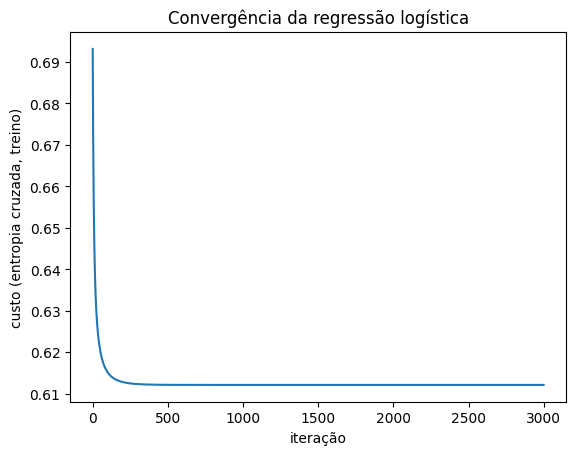

In [19]:
import os
from sklearn.linear_model import LogisticRegression

ATRIBUTOS = ["regiao", "LEUCOPENIA", "faixa_etaria", "VOMITO", "CEFALEIA", "HIPERTENSA"]
for f in ["treino_etapa1.csv", "teste_etapa1.csv"]:
    assert os.path.exists(f), f"suba o arquivo {f} (da Etapa 1) para o Colab"

tr = pd.read_csv("treino_etapa1.csv", dtype=str)
te = pd.read_csv("teste_etapa1.csv", dtype=str)
print(tr.shape, te.shape)            # esperado: (47504, 7) (11876, 7)

ytr_c = tr["alvo"].astype(int).values
yte_c = te["alvo"].astype(int).values

# atributos categóricos -> colunas 0/1 (mesmas colunas para treino e teste)
todos = pd.get_dummies(pd.concat([tr[ATRIBUTOS], te[ATRIBUTOS]], keys=["tr", "te"]),
                       drop_first=True).astype(float)
Xc_tr, Xc_te = todos.loc["tr"].values, todos.loc["te"].values
nomes = list(todos.columns)
Xc_tr1 = np.c_[np.ones(len(Xc_tr)), Xc_tr]      # coluna de 1s (intercepto)
Xc_te1 = np.c_[np.ones(len(Xc_te)), Xc_te]


def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def log_loss(y, p):
    eps = 1e-12
    return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

def gd_logistica(X, y, n_iter=3000):
    N, d = X.shape
    L = 0.25 * np.linalg.eigvalsh(X.T @ X / N).max()
    alpha = 1.0 / L
    w = np.zeros(d)
    hist = []
    for it in range(n_iter):
        p = sigmoide(X @ w)
        w = w + alpha * X.T @ (y - p) / N
        hist.append(log_loss(y, p))
    return w, hist

def acuracia_log(w, X, y):
    return np.mean((sigmoide(X @ w) >= 0.5).astype(int) == y)


w_log, hist = gd_logistica(Xc_tr1, ytr_c)
print("custo inicial -> final:", round(hist[0], 5), "->", round(hist[-1], 5))
print(f"acurácia treino: {acuracia_log(w_log, Xc_tr1, ytr_c):.4f}")
print(f"acurácia teste : {acuracia_log(w_log, Xc_te1, yte_c):.4f}")

# matriz de confusão no teste
pred = (sigmoide(Xc_te1 @ w_log) >= 0.5).astype(int)
vn = np.sum((pred == 0) & (yte_c == 0)); fp = np.sum((pred == 1) & (yte_c == 0))
fn = np.sum((pred == 0) & (yte_c == 1)); vp = np.sum((pred == 1) & (yte_c == 1))
print(f"\nmatriz de confusão (teste): VN={vn} FP={fp} FN={fn} VP={vp}")
print(f"precisão={vp / (vp + fp):.4f} | recall={vp / (vp + fn):.4f}")

# comparação com o scikit-learn (sem regularização: C muito grande)
sk = LogisticRegression(C=1e10, max_iter=10000, tol=1e-10).fit(Xc_tr, ytr_c)
print(f"\nsklearn: treino={sk.score(Xc_tr, ytr_c):.4f} | teste={sk.score(Xc_te, yte_c):.4f}")
print("max |coef sklearn - nosso| =",
      float(np.max(np.abs(np.r_[sk.intercept_, sk.coef_.ravel()] - w_log))))

# coeficientes e razões de chance (odds ratio = exp(coef))
tab = pd.DataFrame({"coef": w_log[1:], "odds_ratio": np.exp(w_log[1:])}, index=nomes).round(4)
print("\n", tab.sort_values("coef", ascending=False).to_string())

plt.plot(hist)
plt.xlabel("iteração"); plt.ylabel("custo (entropia cruzada, treino)")
plt.title("Convergência da regressão logística")
plt.show()

In [20]:
# reconstrói treino/teste da Etapa 1 (mesma lógica e mesma semente)
ATRIBUTOS = ["regiao", "LEUCOPENIA", "faixa_etaria", "VOMITO", "CEFALEIA", "HIPERTENSA"]

dd = pd.read_csv(CAMINHO_CSV, sep=",", encoding="latin-1",
                 usecols=["HOSPITALIZ", "NU_IDADE_N", "SG_UF_NOT", "VOMITO",
                          "LEUCOPENIA", "CEFALEIA", "HIPERTENSA"], low_memory=False)
print("registros no arquivo:", len(dd))            # esperado: 470451

def regiao(x):
    if pd.isna(x):
        return "ignorado"
    d = str(int(float(x)))[0]
    return {"1": "norte", "2": "nordeste", "3": "sudeste",
            "4": "sul", "5": "centro-oeste"}.get(d, "ignorado")

dd = dd[dd["HOSPITALIZ"].isin([1, 2])].copy()
print("com desfecho válido:", len(dd))             # esperado: 346765
dd["alvo"] = (dd["HOSPITALIZ"] == 1).astype(int)
dd["faixa_etaria"] = dd["NU_IDADE_N"].apply(faixa_etaria)
dd["regiao"] = dd["SG_UF_NOT"].apply(regiao)

base = dd[ATRIBUTOS + ["alvo"]].copy()
for a in ATRIBUTOS:
    base[a] = base[a].fillna("ignorado").astype(str)

pos = base[base["alvo"] == 1]
neg = base[base["alvo"] == 0].sample(n=len(pos), random_state=SEED)
bal = pd.concat([pos, neg]).sample(frac=1, random_state=SEED).reset_index(drop=True)
tr, te = train_test_split(bal, test_size=0.2, random_state=SEED, stratify=bal["alvo"])
tr = tr.reset_index(drop=True)
te = te.reset_index(drop=True)
print("treino:", tr.shape, "| teste:", te.shape)   # esperado: (47504, 7) (11876, 7)

tr.to_csv("treino_etapa1.csv", index=False)
te.to_csv("teste_etapa1.csv", index=False)

registros no arquivo: 470451
com desfecho válido: 346765
treino: (47504, 7) | teste: (11876, 7)


custo inicial -> final: 0.69315 -> 0.61213
acurácia treino: 0.6657
acurácia teste : 0.6643

matriz de confusão (teste): VN=3838 FP=2100 FN=1887 VP=4051
precisão=0.6586 | recall=0.6822

sklearn: treino=0.6657 | teste=0.6643
max |coef sklearn - nosso| = 8.29698887871988e-07

                         coef  odds_ratio
regiao_nordeste       1.0957      2.9911
regiao_norte          0.8936      2.4439
faixa_etaria_idoso    0.7381      2.0919
CEFALEIA_2.0          0.6143      1.8484
regiao_sul            0.2900      1.3365
faixa_etaria_crianca  0.2780      1.3205
regiao_sudeste       -0.1221      0.8851
HIPERTENSA_2.0       -0.5617      0.5703
VOMITO_2.0           -0.6049      0.5461
LEUCOPENIA_2.0       -1.4528      0.2339


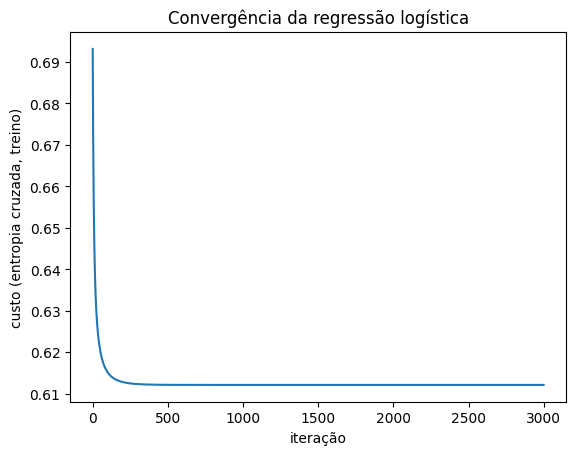

In [21]:
from sklearn.linear_model import LogisticRegression

ytr_c = tr["alvo"].astype(int).values
yte_c = te["alvo"].astype(int).values

# atributos categóricos -> colunas 0/1 (mesmas colunas para treino e teste)
todos = pd.get_dummies(pd.concat([tr[ATRIBUTOS], te[ATRIBUTOS]], keys=["tr", "te"]),
                       drop_first=True).astype(float)
Xc_tr, Xc_te = todos.loc["tr"].values, todos.loc["te"].values
nomes = list(todos.columns)
Xc_tr1 = np.c_[np.ones(len(Xc_tr)), Xc_tr]      # coluna de 1s (intercepto)
Xc_te1 = np.c_[np.ones(len(Xc_te)), Xc_te]


def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def log_loss(y, p):
    eps = 1e-12
    return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

def gd_logistica(X, y, n_iter=3000):
    N, d = X.shape
    L = 0.25 * np.linalg.eigvalsh(X.T @ X / N).max()
    alpha = 1.0 / L
    w = np.zeros(d)
    hist = []
    for it in range(n_iter):
        p = sigmoide(X @ w)
        w = w + alpha * X.T @ (y - p) / N
        hist.append(log_loss(y, p))
    return w, hist

def acuracia_log(w, X, y):
    return np.mean((sigmoide(X @ w) >= 0.5).astype(int) == y)


w_log, hist = gd_logistica(Xc_tr1, ytr_c)
print("custo inicial -> final:", round(hist[0], 5), "->", round(hist[-1], 5))
print(f"acurácia treino: {acuracia_log(w_log, Xc_tr1, ytr_c):.4f}")
print(f"acurácia teste : {acuracia_log(w_log, Xc_te1, yte_c):.4f}")

# matriz de confusão no teste
pred = (sigmoide(Xc_te1 @ w_log) >= 0.5).astype(int)
vn = np.sum((pred == 0) & (yte_c == 0)); fp = np.sum((pred == 1) & (yte_c == 0))
fn = np.sum((pred == 0) & (yte_c == 1)); vp = np.sum((pred == 1) & (yte_c == 1))
print(f"\nmatriz de confusão (teste): VN={vn} FP={fp} FN={fn} VP={vp}")
print(f"precisão={vp / (vp + fp):.4f} | recall={vp / (vp + fn):.4f}")

# comparação com o scikit-learn (sem regularização: C muito grande)
sk = LogisticRegression(C=1e10, max_iter=10000, tol=1e-10).fit(Xc_tr, ytr_c)
print(f"\nsklearn: treino={sk.score(Xc_tr, ytr_c):.4f} | teste={sk.score(Xc_te, yte_c):.4f}")
print("max |coef sklearn - nosso| =",
      float(np.max(np.abs(np.r_[sk.intercept_, sk.coef_.ravel()] - w_log))))

# coeficientes e razões de chance (odds ratio = exp(coef))
tab = pd.DataFrame({"coef": w_log[1:], "odds_ratio": np.exp(w_log[1:])}, index=nomes).round(4)
print("\n", tab.sort_values("coef", ascending=False).to_string())

plt.plot(hist)
plt.xlabel("iteração"); plt.ylabel("custo (entropia cruzada, treino)")
plt.title("Convergência da regressão logística")
plt.show()